In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters

In [2]:
image = data.camera()   # already grayscale
image = (image * 1).astype(np.uint8)  # ensure uint8 format

In [3]:
def iterative_global_threshold(img, delta_T=1):
    """Iterative global thresholding from Gonzalez & Woods."""
    T = np.mean(img)
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        T_new = 0.5 * (np.mean(G1) + np.mean(G2))
        if abs(T - T_new) < delta_T:
            break
        T = T_new
    return T

T_iter = iterative_global_threshold(image)
binary_iter = np.where(image > T_iter, 1, 0)

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

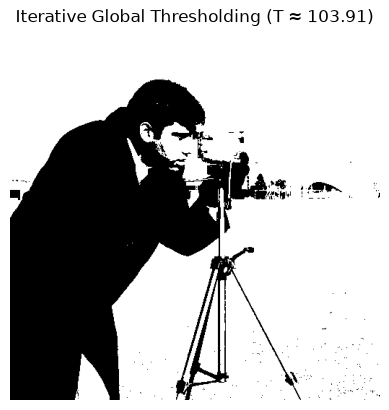

In [4]:
plt.imshow(binary_iter, cmap='gray')
plt.title(f"Iterative Global Thresholding (T ≈ {T_iter:.2f})")
plt.axis('off')